# 04 — Interpretação do melhor modelo

**CMP263 (PPGC/UFRGS, 2026/2)** · Grupo: Artur Mariano, Emerson Herrera e Yaser Husein

**Pergunta:** o que o melhor modelo aprendeu? Quais características das escolas mais pesam na previsão da nota, em que direção, e quanto da previsão depende de saber se a escola é pública ou privada?

O modelo interpretado é o **Gradient Boosting ajustado** do notebook 03 (menor RMSE, 30,63, e melhor posto médio). Os hiperparâmetros (`learning_rate=0.05`, `max_depth=5`, 300 árvores) foram escolhidos nas **15 de 15** buscas da nested CV, então não há nova busca aqui.

| Seção | Método | Pergunta |
|---|---|---|
| 3 | **SHAP** (Aula 08, *Interpretabilidade*) | quais atributos pesam mais e em que direção |
| 4 | variantes **A / B / C** | quanto se perde sem a rede e sem a merenda, num modelo não linear |
| 5 | **resíduos** fora da amostra | que escolas ficam acima ou abaixo do que a estrutura prevê |

## 1. Ambiente

A célula abaixo funciona **localmente** e **no Google Colab**:

- **Local:** rode a partir da raiz do repositório, depois de `uv sync --group notebooks`, e abra com `uv run jupyter lab`.
- **Colab:** a célula clona o repositório e instala as versões fixadas em `requirements.txt`. Se o Colab avisar que precisa reiniciar a sessão (por trocar a versão do pandas/numpy), reinicie e rode tudo de novo.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/emersonheto/enem-school-performance.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo = Path("/content/enem-school-performance")
    if not repo.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo)], check=True)
    os.chdir(repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# Raiz do repositório: funciona com o notebook aberto em notebooks/ ou na raiz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
print("Raiz do repositório:", ROOT.name)
print("Colab:", IN_COLAB)

Raiz do repositório: enem-school-performance
Colab: False


In [2]:
import json
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore", message="IProgress not found")  # shap imports tqdm.auto; no ipywidgets needed
import shap
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import PredefinedSplit, cross_val_predict
from sklearn.pipeline import Pipeline

from enem_school import config
from enem_school.evaluation import spot_check
from enem_school.preprocessing import assign_folds, build_preprocessor, feature_columns

random.seed(config.SEED)
np.random.seed(config.SEED)
pd.set_option("display.precision", 2)

RESULTS_DIR = config.REPORTS_DIR / "results"
FIGURES_DIR = config.REPORTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

BEST = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=config.SEED)

## 2. Dados

A tabela por escola é gerada por `scripts/build_dataset.py`. Se ela ainda não existir (por exemplo, numa sessão nova do Colab), a célula abaixo roda o script, que **baixa cerca de 1 GB do INEP** e leva alguns minutos.

Em seguida conferimos o SHA-256 dos arquivos brutos registrados nos metadados. Se o INEP republicar os microdados, os hashes mudam e a célula falha. Assim, nunca comparamos sem perceber resultados obtidos com dados diferentes.

In [3]:
if not config.SCHOOL_TABLE.exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "build_dataset.py")], check=True, cwd=ROOT)

EXPECTED_SHA256 = {
    "enem": "b8d3e72cbf387ee08f18d552367005429017d43eea1f6d4b9bafe1d83a116071",
    "censo": "ae29d81d45ddecef59e11eda39788cbfd30dfa1cc71be9d29f23051fc2d640db",
}
metadata = json.loads(config.SCHOOL_TABLE_METADATA.read_text(encoding="utf-8"))
for source, expected in EXPECTED_SHA256.items():
    assert metadata["sources"][source]["sha256"] == expected, f"{source}: arquivo do INEP diferente do usado no trabalho"

schools = pd.read_parquet(config.SCHOOL_TABLE)
assert len(schools) == metadata["joined_schools"] == 23_374
print(f"{len(schools):,} escolas, {schools.shape[1]} colunas")
print(f"Alvo: média {schools[config.TARGET].mean():.1f}, desvio {schools[config.TARGET].std():.1f}")

23,374 escolas, 50 colunas
Alvo: média 524.7, desvio 62.4


## 3. SHAP: o que pesa e em que direção

O SHAP decompõe cada previsão em contribuições dos atributos: previsão = média geral + soma das contribuições. Para modelos de árvores, o `TreeExplainer` calcula os valores exatos e rápido.

O modelo é ajustado em **todas** as escolas: aqui queremos **explicar o modelo**, não medir o erro (isso já foi feito na nested CV). Os atributos são os que saem do pré-processamento: contagens em `log(1 + x)` padronizado, binários 0/1 e uma coluna por categoria do one-hot (ex.: `TP_DEPENDENCIA_4` = escola privada).

**Como ler o gráfico:** cada ponto é uma escola. A posição horizontal é quanto aquele atributo empurrou a nota prevista (em pontos do ENEM); a cor é o valor do atributo (vermelho = alto ou "tem", azul = baixo ou "não tem"). Os atributos estão ordenados pela importância média, |SHAP|.

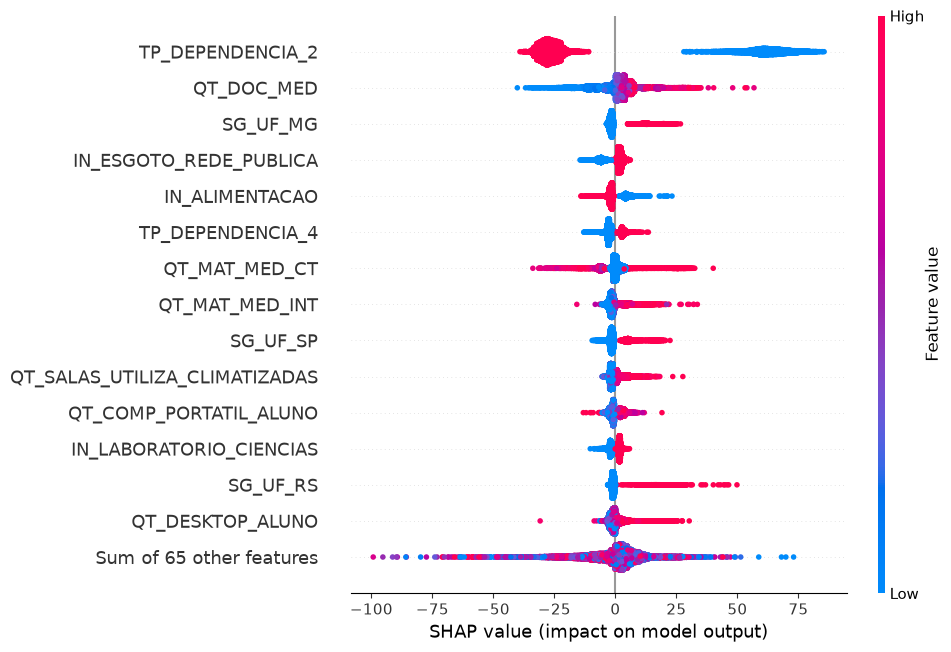

,|SHAP| médio
TP_DEPENDENCIA_2,37.66
QT_DOC_MED,5.24
SG_UF_MG,3.15
IN_ESGOTO_REDE_PUBLICA,2.96
IN_ALIMENTACAO,2.72
TP_DEPENDENCIA_4,2.70
QT_MAT_MED_CT,2.64
QT_MAT_MED_INT,2.64
SG_UF_SP,2.60
QT_SALAS_UTILIZA_CLIMATIZADAS,1.99


In [4]:
X = schools[feature_columns("A")]
y = schools[config.TARGET]
model = Pipeline([("preprocess", build_preprocessor("A")), ("regressor", BEST)]).fit(X, y)

X_model = pd.DataFrame(
    model.named_steps["preprocess"].transform(X),
    columns=model.named_steps["preprocess"].get_feature_names_out(),
)
X_model.columns = X_model.columns.str.replace(r"^(counts|binaries|categorical)__", "", regex=True)
explanation = shap.TreeExplainer(model.named_steps["regressor"])(X_model)

shap.plots.beeswarm(explanation, max_display=15, show=False)
plt.gcf().savefig(FIGURES_DIR / "shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

importance = pd.Series(np.abs(explanation.values).mean(axis=0), index=X_model.columns, name="|SHAP| médio")
importance.sort_values(ascending=False).to_csv(RESULTS_DIR / "shap_importance.csv")
importance.sort_values(ascending=False).head(15).to_frame()

## 4. Variantes A / B / C

Mesmo procedimento do notebook 01, agora também com o Gradient Boosting. As variantes tiram os atributos que funcionam como *proxy* de escola pública/privada:

| Variante | Atributos |
|---|---|
| **A** | todos |
| **B** | sem `TP_DEPENDENCIA` (rede) |
| **C** | sem rede e sem `IN_ALIMENTACAO` (merenda, quase exclusiva da rede pública) |

Se o Gradient Boosting perder **menos** que a regressão linear ao tirar a rede, ele está reconstruindo a rede a partir dos outros atributos (interações que o modelo linear não captura). As partições são as mesmas 3 × 5 dos notebooks 02 e 03.

In [5]:
variants = pd.concat(
    [
        spot_check({"Linear": LinearRegression(), "Gradient Boosting": BEST}, schools, variant=variant).assign(variante=variant)
        for variant in ("A", "B", "C")
    ],
    ignore_index=True,
)
variants.to_csv(RESULTS_DIR / "interpretacao_variantes.csv", index=False)
variants.pivot_table(index="variante", columns="algoritmo", values=["rmse", "r2"], aggfunc="mean")

r2                     rmse       
algoritmo Gradient Boosting Linear Gradient Boosting Linear
variante                                                   
A                      0.76   0.70             30.63  34.24
B                      0.73   0.64             32.46  37.32
C                      0.64   0.50             37.37  43.94

## 5. Resíduos fora da amostra

`cross_val_predict` com as dobras da repetição 1 dá, para cada escola, a previsão de um modelo que **não a viu** no treino. Resíduo = observado − previsto: positivo indica uma escola **acima** do que sua estrutura prevê.

RMSE fora da amostra: 30.70


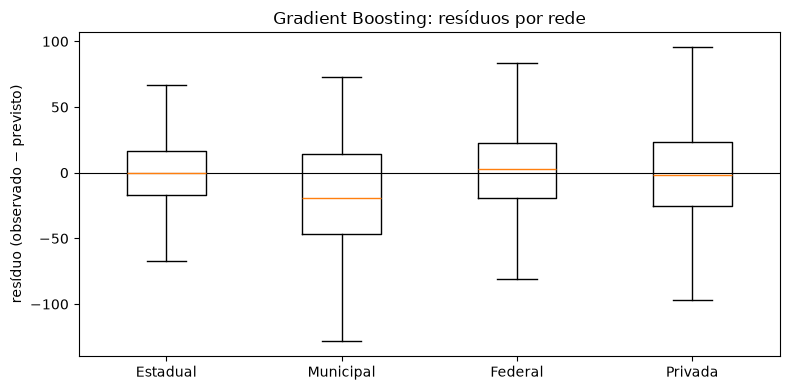

escolas  media  desvio
regiao       rede                             
Centro-Oeste Estadual      1339    2.0    28.2
             Federal         67  -13.4    30.2
             Municipal        4   20.1    19.5
             Privada        474    0.6    37.7
Nordeste     Estadual      4546   -0.9    29.3
             Federal        197   -1.6    31.3
             Municipal        5  -31.9    39.7
             Privada       1437    0.1    39.1
Norte        Estadual      1549   -1.2    28.0
             Federal         68  -12.7    27.3
             Privada        335    0.5    40.3
Sudeste      Estadual      6294    0.3    26.6
             Federal        167   13.1    31.2
             Municipal       68  -18.3    52.4
             Privada       3368   -0.5    36.1
Sul          Estadual      2520    1.8    26.5
             Federal        101    6.5    32.5
             Municipal        7   -1.5    29.3
             Privada        828   -1.9    34.2

In [6]:
predicted = cross_val_predict(
    Pipeline([("preprocess", build_preprocessor("A")), ("regressor", BEST)]), X, y, cv=PredefinedSplit(assign_folds(schools))
)
residuals = schools.assign(
    residuo=y - predicted,
    rede=schools["TP_DEPENDENCIA"].map({1: "Federal", 2: "Estadual", 3: "Municipal", 4: "Privada"}),
    regiao=schools["CO_REGIAO"].map({1: "Norte", 2: "Nordeste", 3: "Sudeste", 4: "Sul", 5: "Centro-Oeste"}),
)
print(f"RMSE fora da amostra: {np.sqrt(np.mean(residuals['residuo'] ** 2)):.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
order = ["Estadual", "Municipal", "Federal", "Privada"]
ax.boxplot([residuals.loc[residuals["rede"] == r, "residuo"] for r in order], tick_labels=order, showfliers=False)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("resíduo (observado − previsto)")
ax.set_title("Gradient Boosting: resíduos por rede")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "interpretacao_residuos.png", dpi=150)
plt.show()

residuals.groupby(["regiao", "rede"])["residuo"].agg(escolas="count", media="mean", desvio="std").round(1)

## 6. Conclusões

**SHAP (seção 3)**
- A **rede domina**: `TP_DEPENDENCIA_2` (escola estadual) tem |SHAP| médio de 37,7 pontos, sete vezes o segundo atributo. Ser estadual tira ≈ 30 pontos da previsão; não ser estadual soma de 50 a 85. O modelo usa "estadual ou não" como o grande corte público/privado (as estaduais são a maior parte das públicas).
- Entre os atributos estruturais, o mais importante é o **número de docentes** (`QT_DOC_MED`): poucos docentes chegam a tirar ≈ 40 pontos.
- A **UF** também pesa: estar em MG, SP ou RS soma pontos, um efeito regional que a estrutura não explica.
- **Direções esperadas:** esgoto da rede pública, laboratório de ciências, salas climatizadas, computadores e matrículas em tempo integral **somam**; a **merenda** (`IN_ALIMENTACAO`) **subtrai**, coerente com ser um *proxy* de escola pública.
- **Menos óbvio:** as matrículas no ensino técnico integrado (`QT_MAT_MED_CT`) aparecem nas duas direções, provavelmente porque misturam institutos federais (notas altas) e escolas técnicas estaduais.

**Variantes (seção 4)**

| | R² Linear | R² Gradient Boosting |
|---|---|---|
| A (tudo) | 0,70 | 0,76 |
| B (sem rede) | 0,64 | 0,73 |
| C (sem rede e merenda) | 0,50 | 0,64 |

- Sem a rede, o Gradient Boosting perde **metade** do que a regressão linear perde (−0,03 contra −0,06 de R²): ele **reconstrói em parte a rede** combinando outros atributos.
- Tirar também a merenda custa mais aos dois (C), mas mesmo assim a estrutura sozinha explica **R² 0,64** com o Gradient Boosting.

**Resíduos (seção 5)**
- Escolas **estaduais e privadas** têm resíduo médio ≈ 0 em todas as regiões: o modelo está calibrado para esses grupos. As **privadas** têm resíduos mais dispersos (desvio ≈ 34–40 contra ≈ 27 nas estaduais): a estrutura explica menos a variação entre privadas, provavelmente por diferenças socioeconômicas dos alunos que o Censo Escolar não mede.
- As **federais** mudam de sinal por região: acima do previsto no Sudeste (+13) e Sul (+7), abaixo no Norte (−13) e Centro-Oeste (−13). O modelo aprende um efeito "federal" médio nacional, com só ≈ 600 escolas.
- As municipais com ensino médio são poucas (≈ 80) e muito dispersas; não dá para concluir sobre elas.

**Limitações:** SHAP explica o **modelo**, não causas: as associações podem refletir o nível socioeconômico dos alunos. Atributos correlacionados (ex.: rede e merenda) dividem a importância entre si.


## Ambiente de execução

Registro das versões usadas, para conferir com `uv.lock`.

In [7]:
import platform

import scipy
import shap
import sklearn

print("Python      ", platform.python_version())
for lib in (np, pd, scipy, sklearn, shap):
    print(f"{lib.__name__:<12}", lib.__version__)
print("Plataforma  ", platform.platform())

Python       3.12.13
numpy        2.5.4
pandas       3.0.6
scipy        1.18.1
sklearn      1.9.1
shap         0.54.1
Plataforma   macOS-27.2-arm64-arm-64bit
